<a href="https://colab.research.google.com/github/vrohithklh/2520090029_DLAC/blob/main/Skill1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [14]:
!pip install -q ultralytics


In [15]:
# 2. IMPORT LIBRARIES
import cv2
import matplotlib.pyplot as plt
from ultralytics import YOLO
from google.colab import files
from IPython.display import display

print("=" * 60)
print("       VISIONPORT OBJECT DETECTION SYSTEM")
print("=" * 60)

       VISIONPORT OBJECT DETECTION SYSTEM


In [16]:
# 3. UPLOAD REAL IMAGE
print("\nUpload a real photograph...")
uploaded = files.upload()

image_path = list(uploaded.keys())[0]


Upload a real photograph...


Saving trafic.jpeg to trafic.jpeg


In [17]:
# 4. LOAD YOLO MODEL
print("\nLoading YOLOv8 pretrained model...")
model = YOLO("yolov8n.pt")

print("Model loaded successfully!")


Loading YOLOv8 pretrained model...
Model loaded successfully!


In [18]:
# 5. IMAGE PREPROCESSING
image = cv2.imread(image_path)

if image is None:
    raise ValueError("Image could not be loaded!")

image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

print("\nImage Acquisition Completed")
print("Original Image Size:", image_rgb.shape)


Image Acquisition Completed
Original Image Size: (501, 847, 3)


In [19]:
# 6. OBJECT DETECTION / INFERENCE
print("\nPerforming Object Detection...")

results = model.predict(
    source=image_path,
    conf=0.25,
    imgsz=640,
    verbose=False
)



Performing Object Detection...


In [20]:
# 7. DRAW BOUNDING BOXES
output_image = results[0].plot()
output_image = cv2.cvtColor(output_image, cv2.COLOR_BGR2RGB)

In [21]:
# 8. DISPLAY DETECTED OBJECTS
print("\nOBJECT DETECTION RESULTS")
print("-" * 50)

boxes = results[0].boxes

if boxes is not None and len(boxes) > 0:

    for i, box in enumerate(boxes):
        class_id = int(box.cls[0])
        confidence = float(box.conf[0])
        object_name = model.names[class_id]

        x1, y1, x2, y2 = map(int, box.xyxy[0])

        print(f"{i+1}. Object: {object_name}")
        print(f"   Confidence: {confidence*100:.2f}%")
        print(f"   Bounding Box: ({x1}, {y1}, {x2}, {y2})")

else:
    print("No objects detected.")


OBJECT DETECTION RESULTS
--------------------------------------------------
1. Object: car
   Confidence: 91.82%
   Bounding Box: (338, 192, 510, 264)
2. Object: car
   Confidence: 88.23%
   Bounding Box: (224, 181, 410, 261)
3. Object: car
   Confidence: 84.11%
   Bounding Box: (208, 372, 377, 496)
4. Object: car
   Confidence: 82.25%
   Bounding Box: (123, 251, 243, 342)
5. Object: person
   Confidence: 77.33%
   Bounding Box: (446, 389, 500, 486)
6. Object: person
   Confidence: 76.48%
   Bounding Box: (599, 322, 652, 414)
7. Object: car
   Confidence: 75.18%
   Bounding Box: (87, 226, 179, 298)
8. Object: person
   Confidence: 72.58%
   Bounding Box: (776, 382, 831, 467)
9. Object: motorcycle
   Confidence: 71.16%
   Bounding Box: (450, 437, 507, 501)
10. Object: person
   Confidence: 69.06%
   Bounding Box: (71, 323, 112, 396)
11. Object: motorcycle
   Confidence: 63.43%
   Bounding Box: (609, 373, 655, 434)
12. Object: car
   Confidence: 60.39%
   Bounding Box: (168, 202, 244, 2

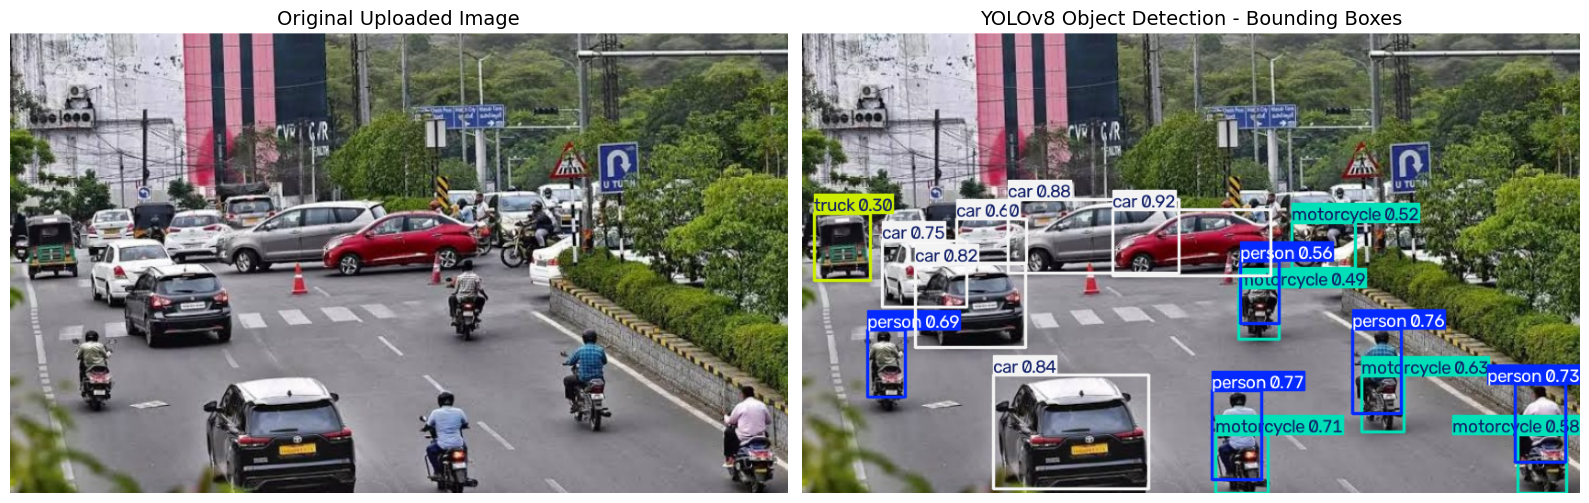

In [22]:
# 9. DISPLAY ORIGINAL AND DETECTED IMAGE
plt.figure(figsize=(16, 8))

plt.subplot(1, 2, 1)
plt.imshow(image_rgb)
plt.title("Original Uploaded Image", fontsize=14)
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(output_image)
plt.title("YOLOv8 Object Detection - Bounding Boxes", fontsize=14)
plt.axis("off")

plt.tight_layout()
plt.show()

In [23]:
# 10. SAVE DETECTED IMAGE
output_path = "VisionPort_Detection_Output.jpg"

cv2.imwrite(
    output_path,
    cv2.cvtColor(output_image, cv2.COLOR_RGB2BGR)
)


True

In [24]:
# 11. FINAL SYSTEM REPORT
print("\n" + "=" * 60)
print("           VISIONPORT SYSTEM REPORT")
print("=" * 60)

print("Image Acquisition       : SUCCESS")
print("Image Preprocessing     : SUCCESS")
print("YOLOv8 Model Loading    : SUCCESS")
print("Object Detection        : SUCCESS")
print("Bounding Box Generation: SUCCESS")
print("Output Visualization    : SUCCESS")
print("Total Objects Detected :", len(boxes))
print("=" * 60)
print("VISIONPORT PIPELINE COMPLETED!")


           VISIONPORT SYSTEM REPORT
Image Acquisition       : SUCCESS
Image Preprocessing     : SUCCESS
YOLOv8 Model Loading    : SUCCESS
Object Detection        : SUCCESS
Bounding Box Generation: SUCCESS
Output Visualization    : SUCCESS
Total Objects Detected : 17
VISIONPORT PIPELINE COMPLETED!


In [25]:
# 12. DOWNLOAD OUTPUT IMAGE
files.download(output_path)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>